# Can an interior photo tell me if a cafe allows laptops?
*CS156 - First Pipeline*

## 1. Introduction

With the city as my campus, I'm always looking for new places to study. Most coffee shops aren't designed for work, so I come prepared: my own internet, a fully charged laptop and headphones. The one thing that still catches me off guard is a **no-laptop policy**. I usually only find out when I arrive, unless someone kindly mentioned it in a Google Maps review.

So the question for this assignment: can a model predict whether a cafe is laptop-friendly from one interior photo on Google Maps? The model outputs a probability that a cafe is laptop-friendly.

- **Label 1 = laptop-friendly** (no policy against laptops), **0 = not friendly**.
- A **false positive** case is when the model says "friendly", I go there, and I'm asked to put the laptop away - potentially rigth before my class. That's a costly mistake, so I care most about precision on the friendly class. A false negative only means I skip a cafe, which is not that bad.

## 2. Pipeline

1. **Data:** one interior photo per cafe from Google Maps + a label from my own experience or reviews (66 cafes, inluding 50 in Berlin and 16 in Paris).
2. **Features:** I thought of two ways of turning a photo into numbers:
   - raw pixels (crop + resize to 64×64, flatten),
   - a pretrained convolutional neural network ResNet-18 that turns each photo into 512 numbers embedding describing what's in it.
3. **Models:** three comparison conditions, all running logistic regression: raw pixels, Principal Component Analysis (PCA), and ResNet features.
4. **Evaluation:** stratified (equal) 5-fold cross validation, repeated 10 times, AUC + accuracy/precision/recall.
5. **Checks:** different k, shuffled labels (what does luck look like?), training vs. unseen cafes, each city separately.

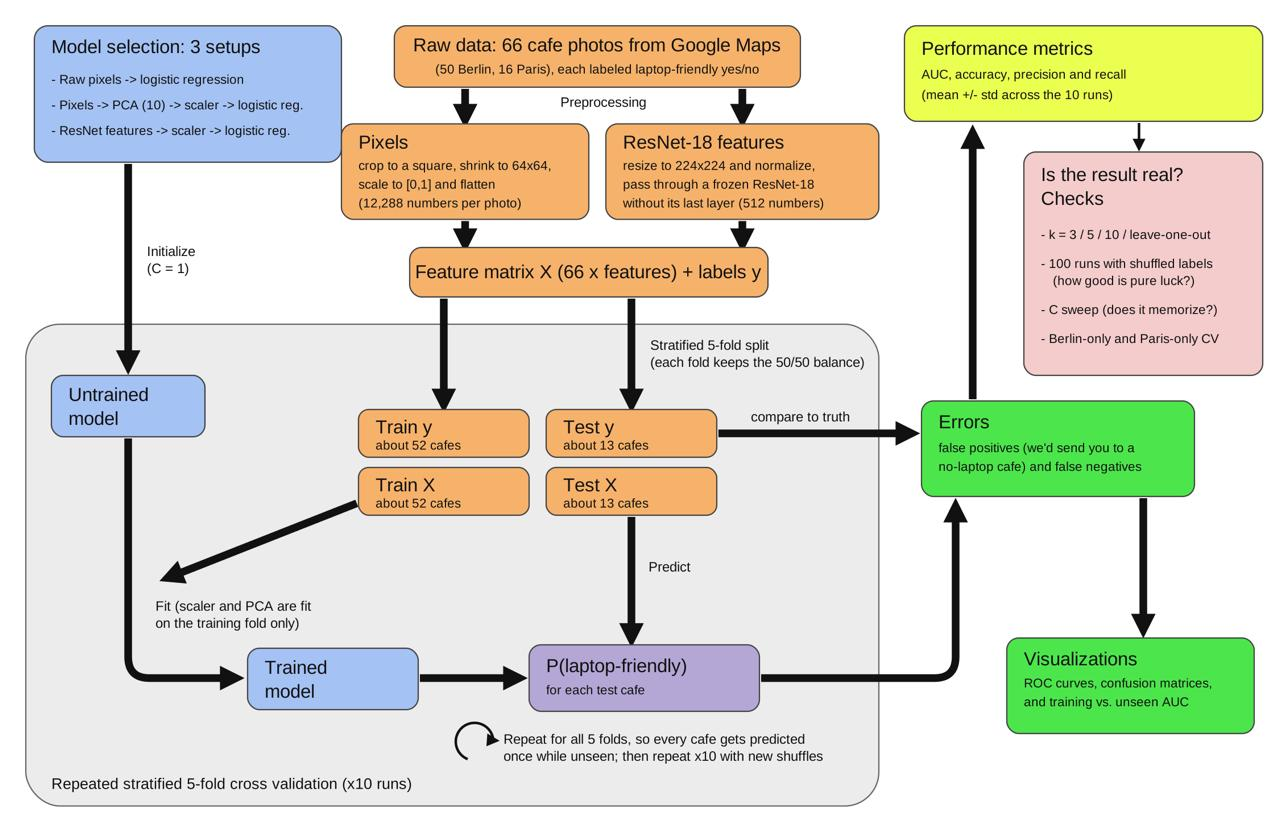

In [79]:
import numpy
import pandas
import matplotlib
import PIL
import sklearn
import torch
import torchvision
print("numpy", numpy.__version__, "sklearn", sklearn.__version__, "torch", torch.__version__)

from torchvision.models import resnet18, ResNet18_Weights
_ = resnet18(weights=ResNet18_Weights.DEFAULT) # downloads 45 MB
print("ResNet-18 weights cached")

numpy 2.5.4 sklearn 1.9.1 torch 2.14.1
ResNet-18 weights cached


In [80]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from torchvision.models import resnet18, ResNet18_Weights

# import collected data
IMAGE_DIR  = "data/images"
LABELS_CSV = "data/cafe-labels.csv"
# set global variables
PIXELS_SIZE = 64
SEED = 0

## 3. Data

One wide-angle interior photo per cafe, taken from cafe's Google Maps tab (posted either by the cafe itself or by customers). I picked photos that show the room from afar. The label comes from my own visits or from Google Maps reviews that mention a laptop policy.

I collected 66 cafes - 50 in Berlin (half laptop friendly, half not) and 16 in Paris (half, half). My first version had only 10 Paris cafes and 21 in Berlin with huge disbalance betweeen laptop friendly and not, so I added more friendly cafes to make both cities and classes balanced.

Every cafe has exactly one photo, so the same cafe will not end up in training and testing, falsely inflating the results.

The labels are a csv (`cafe-labels.csv`: label, name, Google Maps link, city, filename) and the photos are jpg format in `data/images/` (not uploaded to GitHub, since they're Google Maps photos and not of my own). The code below loads the csv, checks that every image exists.

In [81]:
df = pd.read_csv(LABELS_CSV)

print(df.shape)
print(pd.crosstab(df["city"], df["laptop-friendly"], margins=True)) # laptop-friendly vs not, per city

# make sure every file exists
for filename in df['filename']:
    assert os.path.isfile(os.path.join(IMAGE_DIR,filename)), f"missing image: {filename}"



(66, 5)
laptop-friendly   0   1  All
city                        
Berlin           25  25   50
Paris             8   8   16
All              33  33   66


### Preprocessing. Raw pixels
The photos come in different sizes (portrait or landscape), so each one is cropped to center to a square and resized to 64x64 pixels. Values are scaled to [0, 1] and each image is flattened into one long vector of size 64 × 64 × 3 colors = 12,288 pixel values. I don't expect pixels to capture things like table size or how many seats there are - this is the baseline.

In [82]:
# pre process the photos into numpy vectors 
def load_image(filename, size=PIXELS_SIZE):
    image = Image.open(os.path.join(IMAGE_DIR,filename))
    image = image.convert("RGB") # convert to RGB
    image = ImageOps.fit(image, (size, size), method=Image.BILINEAR, centering=(0.5, 0.5)) # crop photos to a sizexsize square, centered not stretched
    return np.asarray(image) / 255 # return values [0,1]

# stack all images
images = np.stack([load_image(filename) for filename in df["filename"]]) # (n images, size, size pixels, 3 colors)
print("images: ",images.shape)
X_pixels = images.reshape(len(images), -1) # flatten each image matrix into 1d vector
assert X_pixels.shape == (len(df), PIXELS_SIZE * PIXELS_SIZE * 3)

y = df["laptop-friendly"].to_numpy()

images:  (66, 64, 64, 3)


### PCA
PCA is supposed to find the directions in which the photos differ the most. By keeping top 10 directions, I squeeze my 12,288 pixel values into 10 variables, which should leave less room for noise. Inside models, I use scikit-learn's (2009) PCA, which computes the same thing as below, but fits into built-in function `make_pipeline()`.

In [83]:
def pca_fit(X, n_components):
    """
    Run a PCA
    Return mean image, top principal directions, fractions of variance explained by each direction 
    Adapted from CS156 Class Notes
    """
    mean = X.mean(axis=0) # mean image
    _, S, Vt = np.linalg.svd(X - mean, full_matrices=False)
    explained = (S ** 2) / np.sum(S ** 2)
    return mean, Vt[:n_components], explained[:n_components]

# Project data onto the principal directions
def pca_transform(X, mean, components):
    return (X - mean) @ components.T

### ResNet-18 
ResNet-18 is a convolutional neural network trained on ImageNet with 1.2M photos, 1000 categories (He et al., 2015). I use it pretrained, since training one would not be possible with my compute power and dataset size. Instead, I remove its last layer that gives the final classification, so it outputs a vector of size 512 describing what it sees (shapes, textures, objects). Each photo is resized to 224×224 and normalized the way ResNet expects with function `weights.transforms()` (He et al., 2015).

We didn't cover ResNet in class. Its key idea is the residual block - when in each block a learns a correction that is added to its input, and not a gulll transformation:

$$\mathbf{h}_{l+1} = \mathrm{ReLU}\big(\mathbf{h}_l + F(\mathbf{h}_l; W_l)\big)$$

where $\mathbf{h}_l$ is the output of block $l$, and $F$ is two convolution layers. The "+ $\mathbf{h}_l$" (skip connection) lets signal and the gradients pass through, making possible training much deeper neural networks (He et al., 2016).

By training logistic regression on these 512-dim embedding, I'm basically training only ResNet's final layer on my data and keep other parts of it untouched. This process is also called transfer learning.

In [84]:
def load_resnet():
    """
    Load the resnet-18 model, dropping the final layer
    Outputs an embedding of dimension 512
    """
    weights = ResNet18_Weights.DEFAULT
    model = resnet18(weights=weights)

    # remove the imagenet classes layer, we only work with features
    model.fc = torch.nn.Identity()
    model.eval() # inference mode
    return model, weights.transforms()

def extract_resnet(df, model, preprocess):
    """
    Run all photos through Resnet-18
    """
    images = []
    for filename in df["filename"]:
        with Image.open(os.path.join(IMAGE_DIR, filename)) as image:
            images.append(preprocess(image.convert("RGB"))) # full original image
    with torch.no_grad(): # dont use gradients
        return model(torch.stack(images)).numpy()

resnet_model, preprocess = load_resnet()
X_resnet = extract_resnet(df, resnet_model, preprocess)
print("resnet shape:", X_resnet.shape) # (n, 512)

resnet shape: (66, 512)


## 4. Models (comparison conditions)

| Condition | Features | Model |
|---|---|---|
| baseline logistic | 12,288 raw pixels | logistic regression |
| PCA logistic | pixels → top 10 PCA components → standardized | logistic regression |
| resnet logistic | 512 ResNet features → standardized | logistic regression |

The sklearn's `LogisticRegression` maximizes the likelyhood, while also adding a penalty for large weights:

$$\hat{\mathbf{w}} = \arg\min_{\mathbf{w}, b} \; -\sum_{i=1}^{n} \Big[y_i \log \sigma(\mathbf{w}^\top \mathbf{x}_i + b) + (1-y_i) \log\big(1-\sigma(\mathbf{w}^\top \mathbf{x}_i + b)\big)\Big] + \frac{1}{2C}\lVert \mathbf{w} \rVert^2, \qquad \sigma(z) = \frac{1}{1+e^{-z}}$$

The last term of the equation pushes weights toward zero. The variable C stands for regularization, small C enforces strong penalty, a simple model with less weights. This is a way to avoid overfitting - which is at high risk with 512 or 12,288 features and max 65 training cafes. 

In [85]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

features = {"pixels": X_pixels, "resnet": X_resnet}
combinations={
    "baseline logistic": ("pixels", lambda:  LogisticRegression(max_iter=1000)),
    # StandardScaler rescales each feature to mean 0 and std 1, to be compatible with resnet and PCA
    "PCA logistic": ("pixels", lambda: make_pipeline(PCA(n_components=10, svd_solver="full"), StandardScaler(),LogisticRegression(max_iter=1000))), # full = exact svd, same result every run
    "resnet logistic": ("resnet", lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
}


## 5. Evaluation

Cross validation.
We only have 66 datapoints - and a single train-test data split would leave 13 test cafes. I use **stratified kfold cross validation**, split the cafes into 5 groups each with the 50/50 laptop-friendly ratio. We choose k=5 so each model trains on 52 cafes and tests on 13.

In [86]:
# set up evaluation system
from sklearn.model_selection import StratifiedKFold  
from sklearn.metrics import (roc_auc_score, accuracy_score,
                             precision_score, recall_score, confusion_matrix)

def fold(y, k=5, seed=SEED):
    """
    Split the data points into k folds, preserving the ratio of laptop-friendly vs not in each fold
    """
    folder = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    return list(folder.split(np.zeros(len(y)), y))

def cross_validation(train_model, X, y, folds):
    """
    Train a model on each training fold
    """
    probabilities = np.full(len(y), np.nan)
    for train, test in folds:
        model = train_model().fit(X[train], y[train])
        probabilities[test] = model.predict_proba(X[test])[:,1]  # P(laptop-friendly)
    return probabilities

def evaluate(y, probabilities, threshold=0.5):
    """
    All metrics for one model
    Adapted from CS156 PCW
    """
    y_pred = (probabilities >= threshold).astype(int)
    return {
          "AUC": roc_auc_score(y, probabilities), # 0.5 is random guessing
          "accuracy": accuracy_score(y, y_pred), # 0.5 is accuracy when we classify all with one label
          "precision": precision_score(y, y_pred, zero_division=0), # tp/(fp+tp)
          "recall": recall_score(y, y_pred, zero_division=0), # tp/(fn+tp)
          "confusion_matrix": confusion_matrix(y, y_pred),
      }

folds = fold(y)

results = {}
probabilities_by_model = {}  # keep the predictions for the ROC plot
for name, (feature, make_model) in combinations.items():
    probabilities = cross_validation(make_model, features[feature], y, folds)
    probabilities_by_model[name] = probabilities
    results[name] = evaluate(y, probabilities)
    print(f"{name:>18} | AUC {results[name]['AUC']:.3f}  accuracy {results[name]['accuracy']:.3f}  "
        f"precision {results[name]['precision']:.3f}  recall {results[name]['recall']:.3f}")


 baseline logistic | AUC 0.416  accuracy 0.439  precision 0.438  recall 0.424
      PCA logistic | AUC 0.425  accuracy 0.409  precision 0.406  recall 0.394
   resnet logistic | AUC 0.428  accuracy 0.485  precision 0.486  recall 0.515


,AUC,accuracy,precision,recall
baseline logistic,0.416,0.439,0.438,0.424
PCA logistic,0.425,0.409,0.406,0.394
resnet logistic,0.428,0.485,0.486,0.515


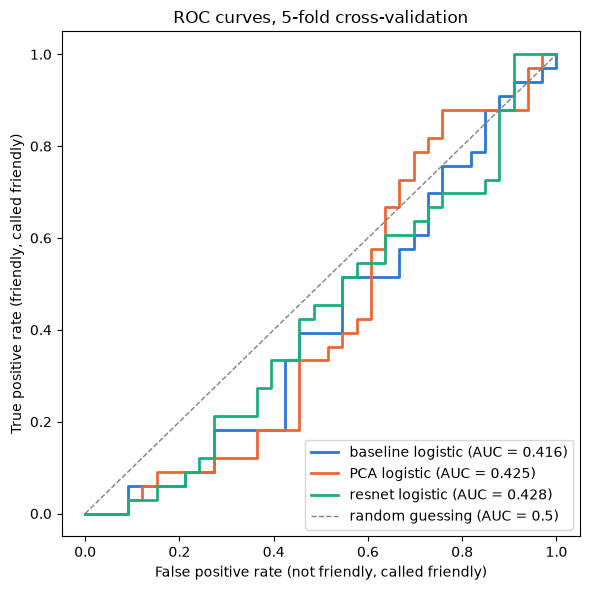

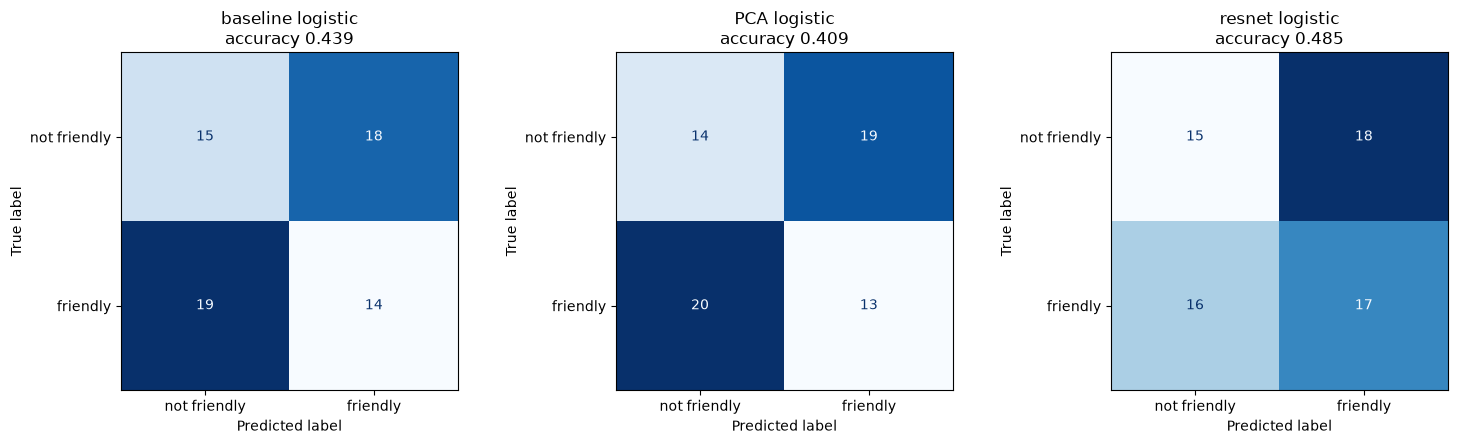

In [87]:
# visualize the results
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

# comparison table
table = pd.DataFrame(results).T.drop(columns="confusion_matrix").astype(float).round(3)
display(table)

# ROC curves
fig, ax = plt.subplots(figsize=(6, 6))
for (name, probabilities), color in zip(probabilities_by_model.items(), COLORS):
    # one point per threshold
    false_positive, true_positive, _ = roc_curve(y, probabilities)
    ax.plot(false_positive, true_positive, color=color, linewidth=2, label=f"{name} (AUC = {results[name]['AUC']:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1, label="random guessing (AUC = 0.5)")
ax.set(xlabel="False positive rate (not friendly, called friendly)",
       ylabel="True positive rate (friendly, called friendly)",
       title=f"ROC curves, {len(folds)}-fold cross-validation")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# confusion matrices- adapted from CS156 PCW
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4.5))
for ax, (name, metrics) in zip(axes, results.items()):
    ConfusionMatrixDisplay(metrics["confusion_matrix"],
                           display_labels=["not friendly", "friendly"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d") # counts instead of %, as n is small
    ax.set_title(f"{name}\naccuracy {metrics['accuracy']:.3f}")
plt.tight_layout()
plt.show()

## 6. Results

| | AUC | accuracy | precision | recall |
|---|---|---|---|---|
| baseline logistic | 0.416 | 0.439 | 0.438 | 0.424 |
| PCA logistic | 0.425 | 0.409 | 0.406 | 0.394 |
| resnet logistic | 0.428 | 0.485 | 0.486 | 0.515 |

On every metric we lookes at all three models are around or slightly below random. The ROC curves wiggle around the diagonal, and there's no threshold where a model finds laptop friendly cafes without falsely classifying as many unfriendly ones. The confusion matrices show the costly mistake directly - the baseline calls 18 of the 33 not-friendly cafes laptop friendly, so in practice I would get turned away from half of the cafes it recommends, with precision 0.44. ResNet is slightly better on precision but still is pretty random.

Looking at the reesults, neither compressing the pixels with PCA nor using ResNet that actually recognizes objects helped. If the problem was too noisy of a data, PCA or ResNet would do better than raw pixels but we see no significant difference. This proposes that interior photos are not a good data to classify a cafe as laptop-friendly or not.

## 7. Is the negative result real?

A single 5-fold run is noisy, so I ran the same cross-valitdation 10 times with random splits.

In [88]:
def repeated_cv(train_model, X, y, k=5, runs=10):
    """
    Run k-fold cross validation several times, shuffle each time
    Return AUC and the average P(laptop-friendly) of every cafe
    """
    aucs, all_probabilities = [], []
    for run in range(runs):
        probabilities = cross_validation(train_model, X, y, fold(y, k=k, seed=run))
        aucs.append(roc_auc_score(y, probabilities))
        all_probabilities.append(probabilities)
    return np.array(aucs), np.mean(all_probabilities, axis=0)

repeated = {}  # name -> (AUC of every run, average probabilities)
for name, (feature, make_model) in combinations.items():
    repeated[name] = repeated_cv(make_model, features[feature], y)
    aucs = repeated[name][0]
    print(f"{name:>18} | AUC {aucs.mean():.3f} ± {aucs.std():.3f}  (min {aucs.min():.3f}, max {aucs.max():.3f}, 10 runs)")

 baseline logistic | AUC 0.442 ± 0.062  (min 0.359, max 0.553, 10 runs)
      PCA logistic | AUC 0.448 ± 0.065  (min 0.306, max 0.524, 10 runs)
   resnet logistic | AUC 0.428 ± 0.012  (min 0.405, max 0.443, 10 runs)


Averages over 10 runs are pixels 0.442 ± 0.062, PCA 0.448 ± 0.065, ResNet 0.428 ± 0.012. A single run can move by up to ±0.1 (the PCA model ranged from 0.31 to 0.52), so one split is not reliable evidence. ResNet's result showed the most stable results, but always below 0.5.

### Does the number of folds matter?
Bigger k makes each model train on more cafes, but test folds get tiny. I even tried the extreme leave-one-out.

In [89]:
from sklearn.model_selection import LeaveOneOut

feature, make_model = combinations["resnet logistic"]
X = features[feature]

for k in [3, 5, 10]:
    aucs, _ = repeated_cv(make_model, X, y, k=k)
    print(f"k={k:<3} trains on ~{len(y) * (k - 1) // k} cafes | AUC {aucs.mean():.3f} ± {aucs.std():.3f}")

# leave-one-out: only one way to split, so one run
loo_probabilities = cross_validation(make_model, X, y, list(LeaveOneOut().split(X)))
print(f"leave-one-out (k={len(y)}) | AUC {roc_auc_score(y, loo_probabilities):.3f}")

k=3   trains on ~44 cafes | AUC 0.430 ± 0.045
k=5   trains on ~52 cafes | AUC 0.428 ± 0.012
k=10  trains on ~59 cafes | AUC 0.408 ± 0.014
leave-one-out (k=66) | AUC 0.383


k = 3, 5 and 10 give nearly the same AUC, and leave-one-out is much worse (0.383). Perhaps, one laptop-firnedly cafe left our brings training data assymmetry and the model learns to non-friendly - making my number sit below 0.5. That's why I went with k=5 insetad.

### How does luck look like?
I shuffled the labels then run the exact same pipeline 100 times. The AUC coming out is a result of pure luck - a good model sould perform better than that. 

I compare a model's real AUC to the shuffled runs:

$$\text{luck score} = \frac{1}{N}\sum_{j=1}^{N} \mathbb{1}\big[\text{AUC}^{\text{shuffled}}_j \geq \text{AUC}^{\text{real}}\big]$$

the share of the N = 100 shuffled runs that did at least as well as the real model. A luck score near 0 means the model found something luck can't explain; around 0.5 or more means the real labels are no better than random ones. (This is the idea behind a permutation test, Ojala & Garriga, 2010.)

shuffled labels: mean AUC 0.495, 95% of luck falls in [0.322, 0.632]
 baseline logistic | 78% of shuffles do at least as well
      PCA logistic | 73% of shuffles do at least as well
   resnet logistic | 81% of shuffles do at least as well


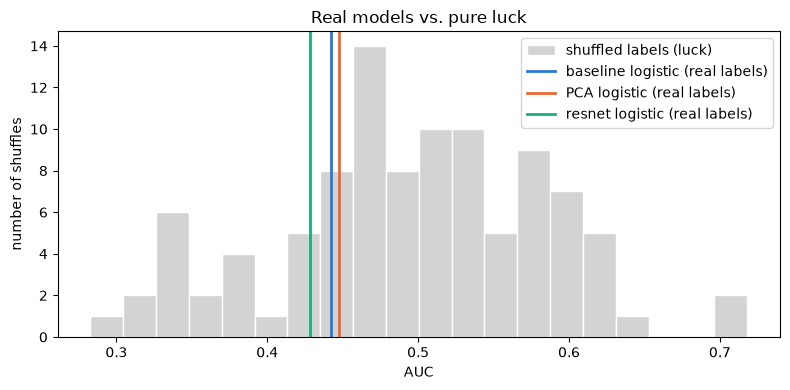

In [90]:
def shuffled_null(train_model, X, y, n_shuffles=100, k=5):
    """
    Shuffle the labels and run cross validation - repeated many times
    Return AUC of every shuffle (the 'luck' distribution)
    """
    rng = np.random.default_rng(SEED)
    aucs = []
    for i in range(n_shuffles):
        y_shuffled = rng.permutation(y)
        probabilities = cross_validation(train_model, X, y_shuffled, fold(y_shuffled, k=k, seed=i))
        aucs.append(roc_auc_score(y_shuffled, probabilities))
    return np.array(aucs)

null_aucs = shuffled_null(combinations["resnet logistic"][1], features["resnet"], y)  # resnet logistic is fast enough for 100 shuffles
low, high = np.percentile(null_aucs, [2.5, 97.5])
print(f"shuffled labels: mean AUC {null_aucs.mean():.3f}, 95% of luck falls in [{low:.3f}, {high:.3f}]")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(null_aucs, bins=20, color="lightgray", edgecolor="white", label="shuffled labels (luck)")
for (name, (aucs, _)), color in zip(repeated.items(), COLORS):
    ax.axvline(aucs.mean(), color=color, linewidth=2, label=f"{name} (real labels)")
    # share of shuffles that did at least as well = how likely this is just luck
    print(f"{name:>18} | {np.mean(null_aucs >= aucs.mean()):.0%} of shuffles do at least as well")
ax.set(xlabel="AUC", ylabel="number of shuffles", title="Real models vs. pure luck")
ax.legend()
plt.tight_layout()
plt.show()

With shuffled labels the AUC has average value 0.495, and 95% of the luck runs fall between 0.32 and 0.63. All three real models land in the middle of that range, with luck scores of 0.78 (pixels), 0.73 (PCA) and 0.81 (ResNet), meaning that about 3 out of 4 random labelings do at least as well as the real labels. So the slightly-below-0.5 AUCs are noise, and the interiior photos contain no useful information about laptop policy.

### What is the model learning? (training vs. unseen cafes)
Here I vary C (from section 4) and compare AUC on the training cafes with AUC on unseen cafes (cross validation).

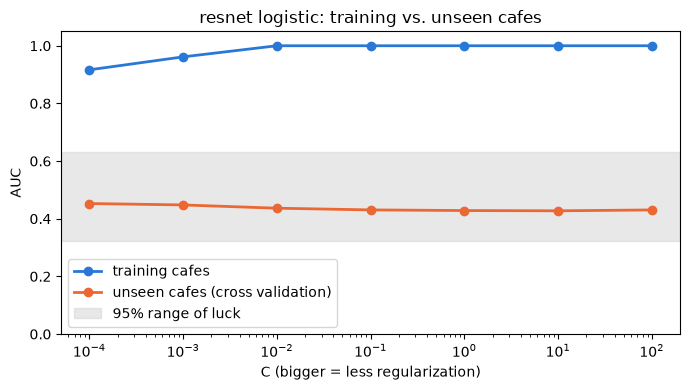

In [91]:
Cs = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
train_auc, cv_auc = [], []
for C in Cs:
    make_model = lambda C=C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000))
    # training AUC: fit on all cafes, score on the same cafes
    model = make_model().fit(features["resnet"], y)
    train_auc.append(roc_auc_score(y, model.predict_proba(features["resnet"])[:, 1]))
    cv_auc.append(repeated_cv(make_model, features["resnet"], y)[0].mean())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Cs, train_auc, "o-", color=COLORS[0], linewidth=2, label="training cafes")
ax.plot(Cs, cv_auc, "o-", color=COLORS[1], linewidth=2, label="unseen cafes (cross validation)")
ax.axhspan(low, high, color="lightgray", alpha=0.5, label="95% range of luck")
ax.set(xscale="log", xlabel="C (bigger = less regularization)", ylabel="AUC", ylim=(0, 1.05),
       title="resnet logistic: training vs. unseen cafes")
ax.legend()
plt.tight_layout()
plt.show()

Training AUC goes to a perfect score 1.0 starting from C = 0.01 - meaning the model separates its training cafes well. However, for unseen cafes it stays at ~0.43-0.45 for any C. Seems like some combination of photos' features can separate the training cafes, but they're not generalizeable at all.

## 8. Discussion

It didn't work - all three conditions perform like a pure chance with AUC ~0.45 over 10 repeated runs. They perform the same with shuffled labels having luck scores 0.73-0.81, and the result holds for every value of k and C I tried. Following the model, I'd get the same results as picking cafes at random.

I think the main reason is that a laptop policy is a rule, not correlated with cafe interiors. The cafe staff decides it, and two cafes with similar wooden tables and plants can have opposite rules. My collected photos show furniture, light and decoration, and not showing laptops. Even ResNet recognizing the tables and chairs in a scene didn't help. 
Another thing is that the data is small - there are not that many laptop-firendly spaces, and 52 training cafes is not enough for hundreds or thousands of features.

Maybe adding several photos per cafe (some show people working on laptops), or even text from Google Maps reviews, where people actually mention laptops. But the text formulation would test a different hypothesis.

## 9. Confounds and limitations

- Photo conditions - time of day, lighting, how crowded the cafe was, and camera angle all differ between photos. The "wide-angle interior shot" rule helps, but doesn't remove this.
- Center crop -  the square crop throws away the edges, more for tall photos than wide ones.
- Labels - come from my own visits or from reviews, so a few could be outdated or wrong.
- Selection - these are cafes I chose to visit or look up, not a random sample of cafes.
- Small data - 66 cafes (16 in Paris), so every number has a wide margin 

## 10. Code and references

**Repository:** https://github.com/aminarhe/ml-cs156/tree/main/First-Pipeline - this notebook contains all the code and outputs. The photos are not included (Google Maps images), only the labels csv.

- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. *CVPR*. https://arxiv.org/abs/1512.03385
- Ojala, M., & Garriga, G. C. (2010). Permutation tests for studying classifier performance. *Journal of Machine Learning Research, 11*, 1833-1863.
- Murphy, K. P. (2022). *Probabilistic Machine Learning: An Introduction*. MIT Press. (logistic regression and regularization)
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *JMLR, 12*, 2825-2830. https://scikit-learn.org
- PyTorch / torchvision pretrained models: https://pytorch.org/vision/stable/models.html
- CS156 class notes and pre-class work (PCA functions, evaluation and confusion matrix code).
- AI assistance: Claude (Anthropic) was used for feedback on the plan and debugging.